In [144]:
#import package
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import  RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import joblib

from sklearn.pipeline import Pipeline


In [145]:
#connect google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Note:** The database link provided in the assignment was not working. Therefore, I downloaded another dataset with the same name from Kaggle and used it to complete this assignment. The dataset used is the same in name and type as the one specified in the assignment.

### **Assignment: Diabetes Prediction Model**

1️⃣ Data Loading & Exploration

In [146]:
#Load dataset using Pandas
df = pd.read_csv("/content/drive/MyDrive/dataset/diabetes.csv")


In [147]:
#Show first few rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [148]:
#Check dataset shape
df.shape

(768, 9)

In [149]:
#Check column names
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [150]:
#Check data types
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [151]:
#info check
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [152]:
#Check missing values
df.isnull().sum().sum()

#note: our data are clean

np.int64(0)

In [153]:
#Basic statistical summary
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [154]:
#Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [155]:
#check zero value
cols = ['Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI']

(df[cols] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


**Note:** Zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI are considered invalid measurements. I replaced them with NaN and will handle them using Median Imputation.

In [156]:

df[cols] = df[cols].replace(0, np.nan)

In [157]:
#Target distribution
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


Exploratory Data Analysis (EDA)

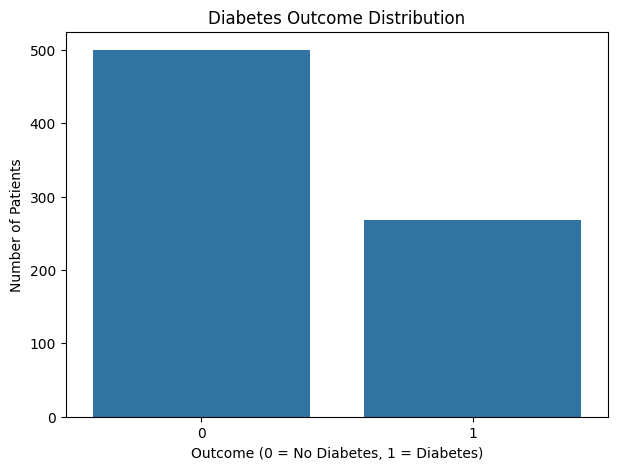

Outcome
0    500
1    268
Name: count, dtype: int64


In [158]:
# Diabetes Outcome Distribution

plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")

plt.show()

print(df["Outcome"].value_counts())

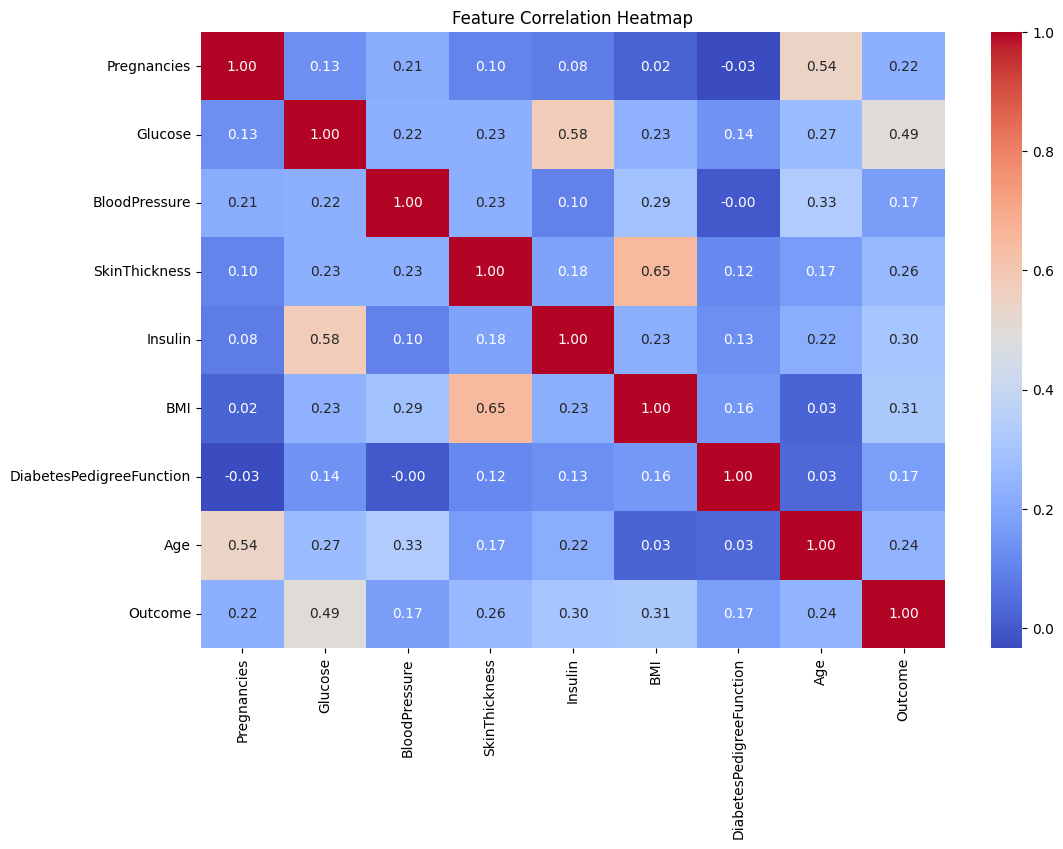

In [159]:
# Correlation Heatmap

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

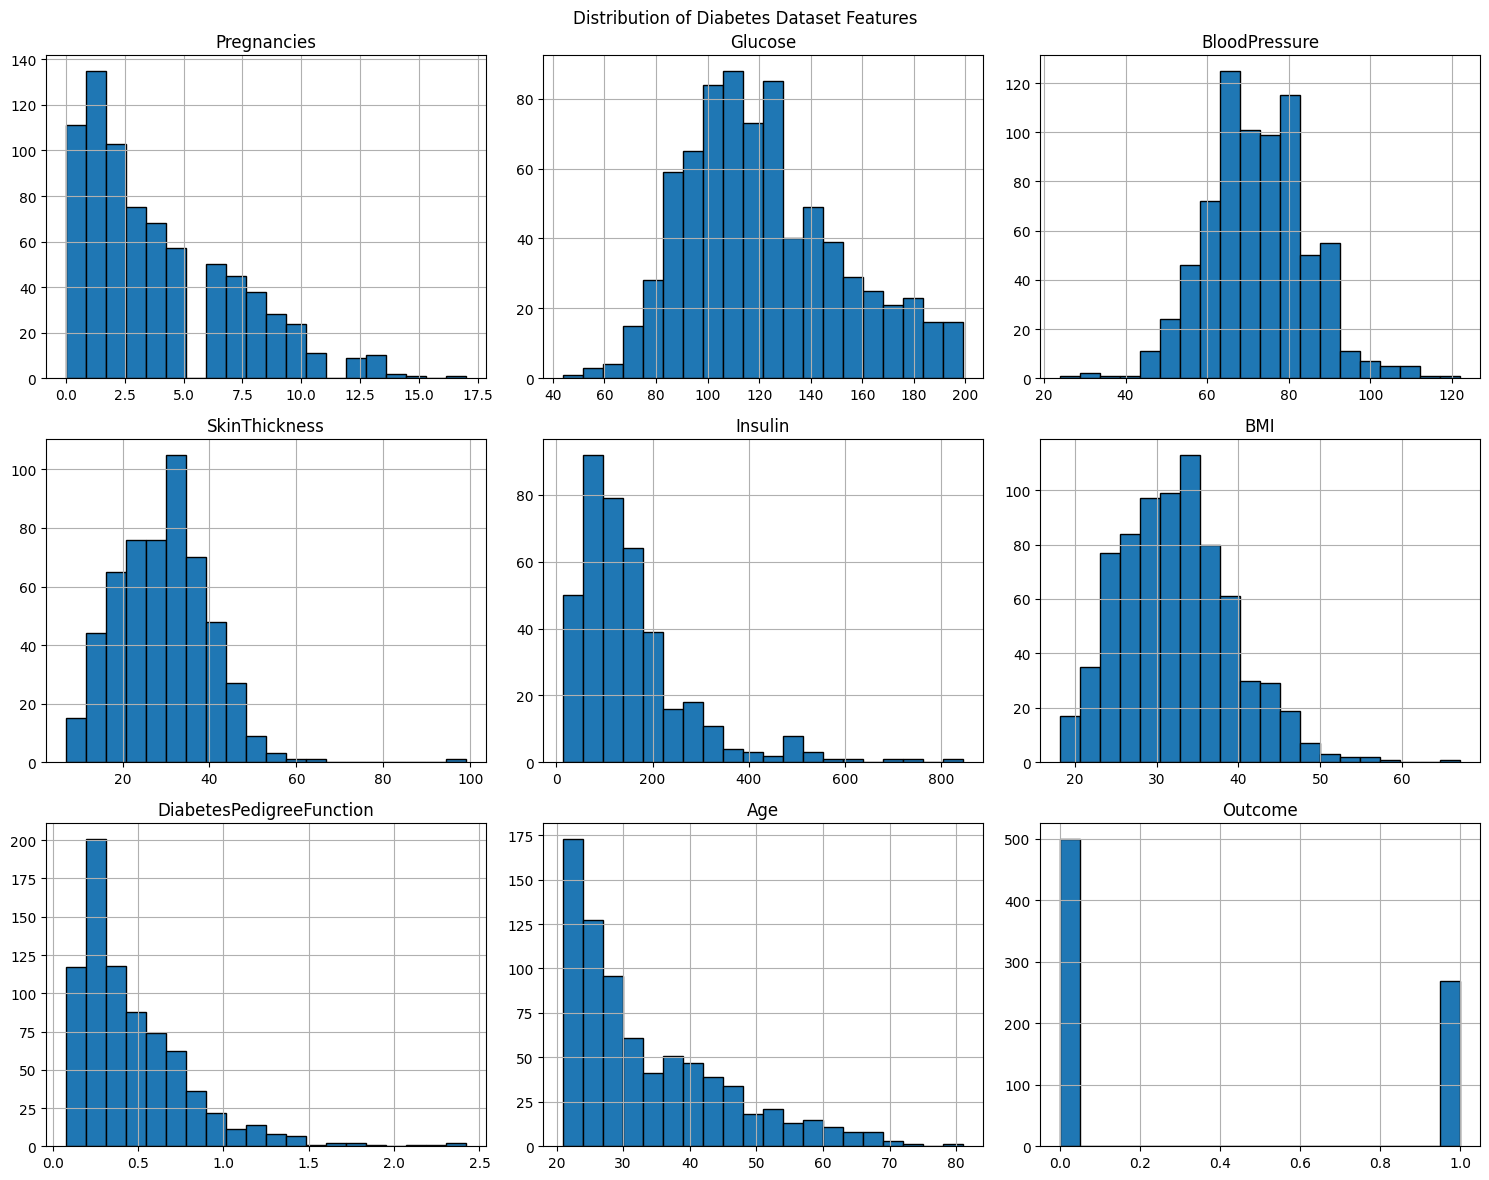

In [160]:
# Feature Distribution

df.hist(
    figsize=(15,12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Diabetes Dataset Features")

plt.tight_layout()

plt.show()

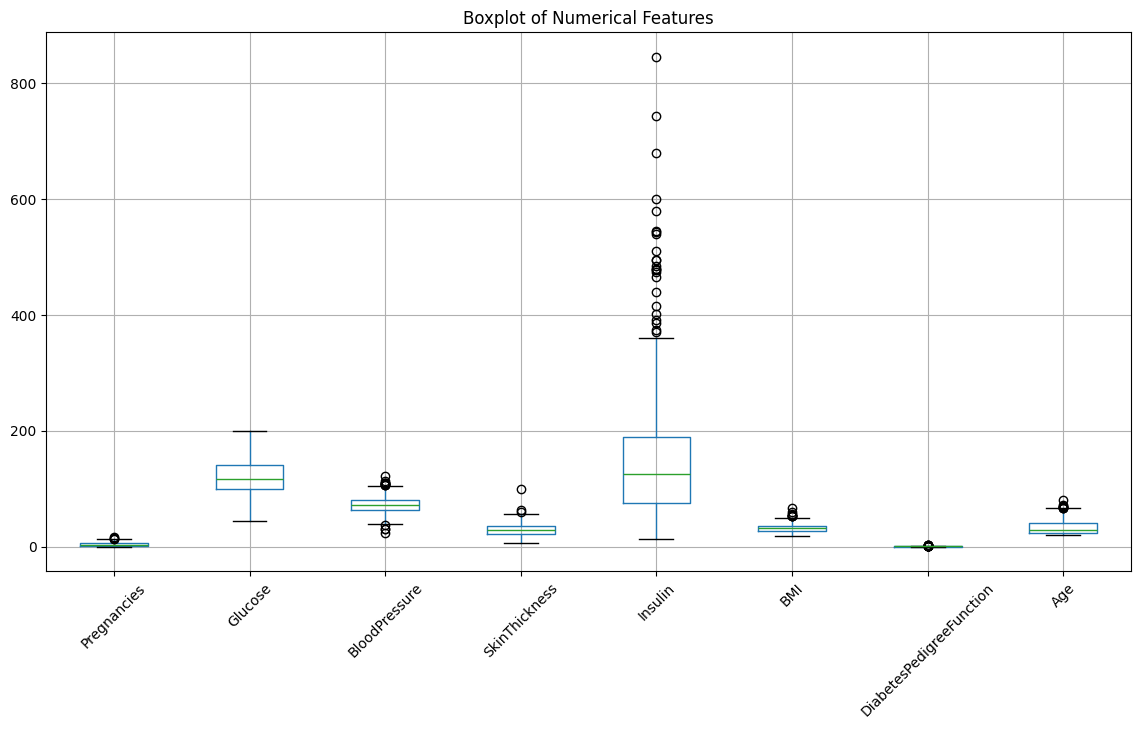

In [161]:
# Outlier Detection using Boxplot

plt.figure(figsize=(14,7))

df.drop(columns="Outcome").boxplot()

plt.title("Boxplot of Numerical Features")

plt.xticks(rotation=45)

plt.show()

2️⃣ Data Preprocessing


In [162]:
#Separate features (X) and target (y)
X=df.drop(columns="Outcome")
y=df["Outcome"]


In [163]:
X.head(5)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [164]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [165]:
X.columns


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

In [166]:
#Perform Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state= 42,
    stratify = y,

)

In [167]:
#print Train/Test  shape
print("X_train shape",X_train.shape)
print("y_train shape",y_train.shape)
print("X_test shape",X_test.shape)
print("y_test shape",y_test.shape)

X_train shape (614, 8)
y_train shape (614,)
X_test shape (154, 8)
y_test shape (154,)


In [168]:
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()
# Median Imputation

imputer = SimpleImputer(strategy="median")

X_train[cols] = imputer.fit_transform(X_train[cols])
X_test[cols] = imputer.transform(X_test[cols])

# Check missing values
print("Training Missing Values:")
print(X_train.isnull().sum().sum())

print("Testing Missing Values:")
print(X_test.isnull().sum().sum())

Training Missing Values:
0
Testing Missing Values:
0


In [169]:
#Class Distribution Check
y_train.value_counts(normalize=True)*100

,proportion
Outcome,
0,65.14658
1,34.85342


In [170]:
y_test.value_counts(normalize=True)*100

,proportion
Outcome,
0,64.935065
1,35.064935


In [171]:
#Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


3️⃣ Model Training

Logistic Regression

In [172]:
lr_model= LogisticRegression( C=0.5,
    max_iter=1000,
    class_weight='balanced',
    random_state=42)

In [173]:
lr_model.fit(X_train_scaled,y_train)

LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000,
                   random_state=42)

In [174]:
lr_model_pred= lr_model.predict(X_test_scaled)

In [175]:
print("Train accuracy:", round(accuracy_score(y_train, lr_model.predict(X_train_scaled)), 4))
print("Test accuracy :", round(accuracy_score(y_test, lr_model_pred), 4))

Train accuracy: 0.7606
Test accuracy : 0.7338


Random Forest

In [176]:
rf_model = RandomForestClassifier( n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42)
rf_model.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=3,
                       min_samples_split=5, n_estimators=300, random_state=42)

In [177]:
rf_model_pred= rf_model.predict(X_test)



Support Vector Machine

In [178]:
svm_model = SVC(
    C=1.0,
    kernel='rbf',
    gamma='scale',
    class_weight='balanced',
    probability=True,
    random_state=42
)
svm_model.fit(X_train_scaled,y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [179]:
svm_model_pred= svm_model.predict(X_test_scaled)

Decision Tree

In [180]:
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)
dt_model.fit(X_train,y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=5,
                       min_samples_split=10, random_state=42)

In [181]:
dt_model_pred = dt_model.predict(X_test)

K-Nearest Neighbors (KNN)

In [182]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights='distance',
    algorithm='auto',
    metric='minkowski',
    p=2
)
knn_model.fit(X_train_scaled,y_train)

KNeighborsClassifier(n_neighbors=7, weights='distance')

In [183]:
knn_model_pred= knn_model.predict(X_test_scaled)

## Model Evaluation


In [184]:
models = {
    "Logistic Regression": (lr_model, X_test_scaled),
    "Random Forest": (rf_model, X_test),
    "SVM": (svm_model, X_test_scaled),
    "DT":(dt_model,X_test),
    "KNN":(knn_model,X_test_scaled)
}

results = []

for name, (model, X_test_data) in models.items():

    y_pred = model.predict(X_test_data)

    # Probability or decision score
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_data)[:, 1]
    else:
        y_score = model.decision_function(X_test_data)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Evaluation Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_test, y_score)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc_score,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    print(f"\n{name}")
    print(classification_report(y_test, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154


Random Forest
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       100
           1       0.63      0.70      0.67        54

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.74       154
weighted avg       0.76      0.75      0.76       154


SVM
              precision    recall  f1-score   support

           0       0.83      0.73      0.78       100
           1       0.59      0.72      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73

In [185]:

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  TN  \
0  Logistic Regression    0.7338     0.6032  0.7037    0.6496   0.8126  75   
1        Random Forest    0.7532     0.6333  0.7037    0.6667   0.8226  78   
2                  SVM    0.7273     0.5909  0.7222    0.6500   0.8139  73   
3                   DT    0.7338     0.6140  0.6481    0.6306   0.7949  78   
4                  KNN    0.7273     0.6200  0.5741    0.5962   0.7931  81   

   FP  FN  TP  
0  25  16  38  
1  22  16  38  
2  27  15  39  
3  22  19  35  
4  19  23  31  


## ROC Curve Comparison

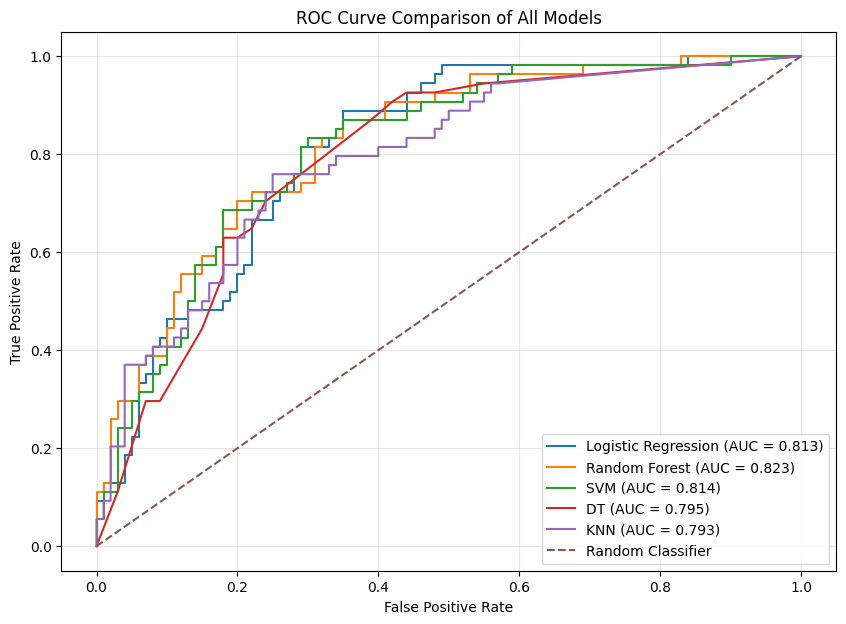

In [186]:
from sklearn.metrics import roc_curve, auc

# Plot ROC Curve for all models

plt.figure(figsize=(10, 7))

for name, (model, X_test_data) in models.items():

    # Get prediction probabilities
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_data)[:, 1]
    else:
        y_score = model.decision_function(X_test_data)

    # Calculate FPR and TPR
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    # Calculate AUC
    roc_auc = auc(fpr, tpr)

    # Plot ROC Curve
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

# Random Classifier Baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of All Models")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.show()

Model Comparison Visualization

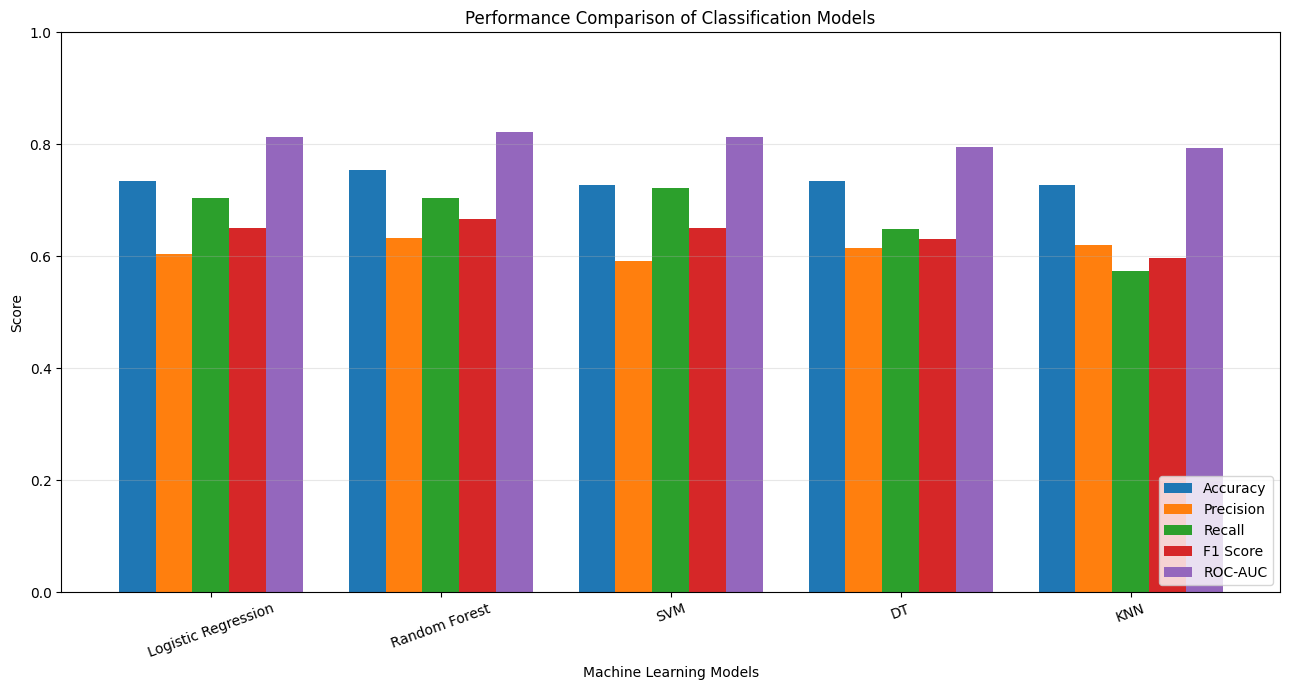

In [187]:
# Model Performance Comparison

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_df = results_df.set_index("Model")[metrics]

comparison_df.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Performance Comparison of Classification Models")

plt.xlabel("Machine Learning Models")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.legend(loc="lower right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

Best Model Selection

In [188]:
# Select Best Model based on F1 Score and ROC-AUC

best_model = results_df.sort_values(
    by=["F1 Score", "ROC-AUC"],
    ascending=False
).iloc[0]

print("Best Performing Model")

print("Model:", best_model["Model"])

print("Accuracy:", round(best_model["Accuracy"], 4))

print("Precision:", round(best_model["Precision"], 4))

print("Recall:", round(best_model["Recall"], 4))

print("F1 Score:", round(best_model["F1 Score"], 4))

print("ROC-AUC:", round(best_model["ROC-AUC"], 4))

Best Performing Model
Model: Random Forest
Accuracy: 0.7532
Precision: 0.6333
Recall: 0.7037
F1 Score: 0.6667
ROC-AUC: 0.8226


Best Model Confusion Matrix

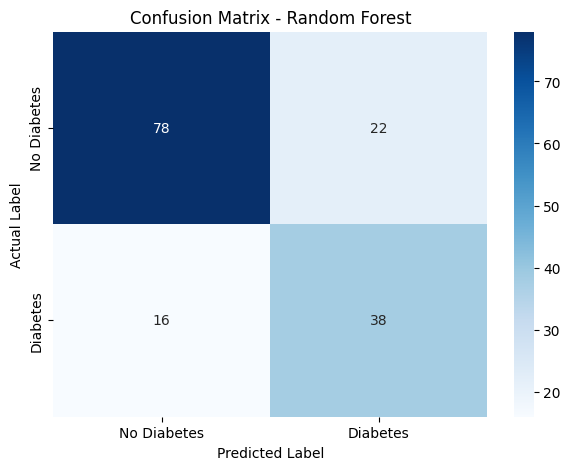

              precision    recall  f1-score   support

 No Diabetes       0.83      0.78      0.80       100
    Diabetes       0.63      0.70      0.67        54

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.74       154
weighted avg       0.76      0.75      0.76       154



In [189]:
# Best Model Confusion Matrix

best_model_name = best_model["Model"]

best_model_object, best_X_test = models[best_model_name]

best_predictions = best_model_object.predict(best_X_test)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title(f"Confusion Matrix - {best_model_name}")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.show()

print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Diabetes", "Diabetes"]
))

 Feature Importance Analysis

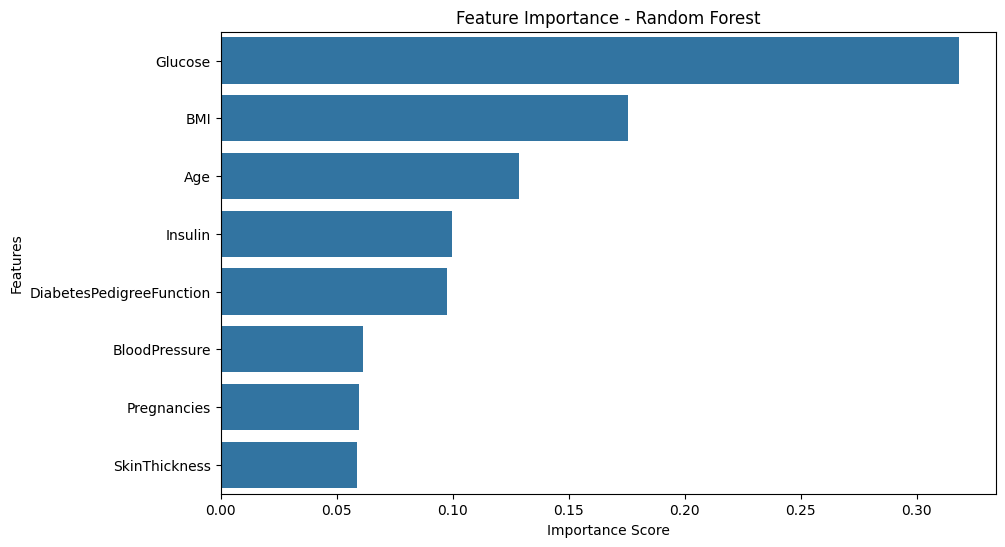

                    Feature  Importance
1                   Glucose    0.318155
5                       BMI    0.175503
7                       Age    0.128828
4                   Insulin    0.099578
6  DiabetesPedigreeFunction    0.097641
2             BloodPressure    0.061473
0               Pregnancies    0.059820
3             SkinThickness    0.059002


In [190]:
# Feature Importance using Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

print(feature_importance)

Save Best Model using Joblib

In [191]:
# Create complete pipeline

final_steps = [
    ("imputer", SimpleImputer(strategy="median"))
]

# Add scaling for models that require scaled data

if best_model_name in [
    "Logistic Regression",
    "SVM",
    "KNN"
]:
    final_steps.append(
        ("scaler", StandardScaler())
    )

# Add selected best model

final_steps.append(
    ("classifier", best_model_object)
)

final_pipeline = Pipeline(final_steps)

# Train complete pipeline on original training data

final_pipeline.fit(X_train_raw, y_train)

# Save model

joblib.dump(final_pipeline, "diabetes_model.pkl")

print("Best Model:", best_model_name)

print("Model saved successfully!")

Best Model: Random Forest
Model saved successfully!


Load and Test Saved Model

In [192]:
# Load saved model

loaded_model = joblib.load("diabetes_model.pkl")



In [193]:
# Predict using test data

sample_prediction = loaded_model.predict(
    X_test_raw.iloc[:5]
)

print("Predictions:", sample_prediction)

print("Actual Values:", y_test.iloc[:5].values)

Predictions: [1 0 0 0 0]
Actual Values: [0 0 0 1 0]


## Conclusion


In this assignment, I developed a Diabetes Prediction Model using the Pima Indians Diabetes Dataset.

I performed data exploration, preprocessing, missing value handling, feature scaling, and train-test splitting.

I trained five different classification algorithms:

1. Logistic Regression
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree
5. K-Nearest Neighbors (KNN)

I evaluated all models using Accuracy, Precision, Recall, F1 Score, and ROC-AUC Score.

I also compared the models using ROC curves, performance visualization, and confusion matrices.

Based on the evaluation results, I selected the best-performing model by considering F1 Score and ROC-AUC.

Finally, I saved the selected model using Joblib for future predictions.

This project helped me understand the complete Machine Learning classification workflow.